Cell 1 – Import libraries

In [5]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

Cell 2 – Upload dataset

In [6]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

# Check if a zip file was uploaded and unzip it
for filename in uploaded.keys():
    if filename.endswith('.zip'):
        print(f"Extracting {filename}...")
        with zipfile.ZipFile(filename, 'r') as zip_ref:
            zip_ref.extractall('.')

# Read the CSV file
csv_filename = 'IMDB Dataset.csv'
if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename)
    print("Dataset loaded!")
    print(df.shape)
    display(df.head())
else:
    print(f"Error: '{csv_filename}' not found. Please ensure the unzipped file exists in your workspace.")

Extracting IMDB Dataset.csv.zip...
Extracting IMDB Dataset.csv (1).zip...
Dataset loaded successfully!
(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Cell 3 – Understand dataset

print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df['sentiment'].value_counts())

Cell 4 – Visualize sentiment distribution

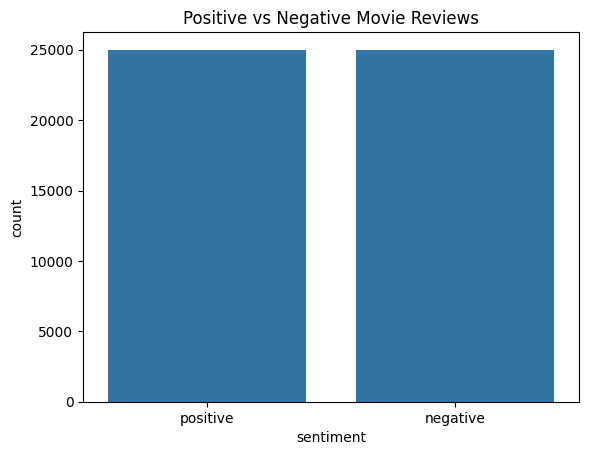

In [7]:
sns.countplot(data=df, x='sentiment')

plt.title('Positive vs Negative Movie Reviews')
plt.show()

Cell 5 – Clean text data

In [8]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['clean_review'] = df['review'].apply(clean_text)

display(df[['review', 'clean_review']].head())

,review,clean_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter matteis love in the time of money is a ...


Cell 6 – Prepare input and target

In [9]:
X = df['clean_review']

y = df['sentiment'].map({
    'negative': 0,
    'positive': 1
})

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50000,)
Target shape: (50000,)


Cell 7 – Split dataset

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 40000
Testing records: 10000


Cell 8 – Build TF-IDF and Logistic Regression model

In [11]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("NLP Model trained successfully!")

NLP Model trained successfully!


Cell 9 – Predict sentiment

In [12]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(results.head(10))

,Actual,Predicted
0,0,0
1,0,1
2,1,1
3,0,0
4,0,0
5,0,0
6,0,0
7,0,1
8,0,0
9,0,0


Cell 10 – Evaluate model

In [13]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

Model Accuracy: 89.53 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      5000
    Positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

